# Benchmark - Data Preparation, Reference Schemes & Truth Eligibility

- **Part A (Run Analysis):** Environment verification, pinned ViroConstrictor configuration (`fc7aa89b085b`), loading the ECDC ESIB EQA cohorts (2023–2026), primer schemes, genomic stratification (`primer_site`, `amplicon_overlap`, `amplicon_unique`), Gold (`high_cov`, 10% ambiguity margin) and Silver (`low_cov`, 20% ambiguity margin) truth alignments, raw read depth profiling, and the prototype equivalence gate against `primer_matchers.py`.
- **Part B (Results & Visualization):** Cohort inventory tables, breakdowns, raw depth eligibility filtering (`EQA_2023_22` and `EQA_2024_12` excluded), and prototype equivalence verification.

**Caching:** Every expensive step checks `if output_path.is_file():` first. If the file exists on disk, the computation is skipped. We have to delete the output file if to re-run that step from scratch.

## Part A, Run Analysis & Prepare Metadata

In [57]:
from dataclasses import dataclass
import gzip
import hashlib
import json
import os
from pathlib import Path
import platform
import re
import shutil
import subprocess
import sys
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd().resolve()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

MANUAL_DIR = ROOT / "manual_test"
DATASET_DIR = MANUAL_DIR / "datasets"
PROCESSED_DIR = MANUAL_DIR / "processed"
RESULTS_DIR = PROCESSED_DIR / "benchmark2"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

REFERENCE_ID = "MN908947.3"
REFERENCE_FASTA = MANUAL_DIR / "MN908947.fasta"
REFERENCE_GFF = MANUAL_DIR / "MN908947.gff"
YEARS = ("2023", "2024", "2025", "2026")
RANDOM_SEED = 42

ENVS = {"main": "ampligone_thesis", "vc": "ampligone_thesis_vc"}
ENV_ROOT = Path(sys.prefix).parent


def env_bin(env_key: str, binary: str) -> Path:
    return ENV_ROOT / ENVS[env_key] / "bin" / binary


def run_cmd(cmd, env_key: str = "main", check: bool = True, **kwargs) -> subprocess.CompletedProcess:
    env_dir = ENV_ROOT / ENVS[env_key] / "bin"
    env = os.environ.copy()
    env["PATH"] = f"{env_dir}:{env.get('PATH', '')}"
    return subprocess.run(cmd, env=env, check=check, text=True, capture_output=True, **kwargs)


def sha256(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for chunk in iter(lambda: handle.read(1 << 20), b""):
            digest.update(chunk)
    return digest.hexdigest()


print(f"Workspace root:   {ROOT}")
print(f"Reference FASTA:  {REFERENCE_FASTA} (exists={REFERENCE_FASTA.is_file()})")
print(f"Reference GFF:    {REFERENCE_GFF} (exists={REFERENCE_GFF.is_file()})")
print(f"Dataset dir:      {DATASET_DIR} (exists={DATASET_DIR.is_dir()})")
print(f"Results dir:      {RESULTS_DIR}")

Workspace root:   /home/zwagemaf/projects/AmpliGone_thesis
Reference FASTA:  /home/zwagemaf/projects/AmpliGone_thesis/manual_test/MN908947.fasta (exists=True)
Reference GFF:    /home/zwagemaf/projects/AmpliGone_thesis/manual_test/MN908947.gff (exists=True)
Dataset dir:      /home/zwagemaf/projects/AmpliGone_thesis/manual_test/datasets (exists=True)
Results dir:      /home/zwagemaf/projects/AmpliGone_thesis/manual_test/processed/benchmark2


In [58]:
# 1. Environment & Tool Version Manifest
ENV_MANIFEST_JSON = RESULTS_DIR / "environment_manifest.json"

if ENV_MANIFEST_JSON.is_file():
    print(f"Skipping environment manifest generation (already exists: {ENV_MANIFEST_JSON})")
else:
    def first_line(cmd, env_key="main") -> str:
        result = run_cmd(cmd, env_key=env_key, check=False)
        text = (result.stdout or result.stderr).strip()
        return text.splitlines()[0] if text else "unavailable"

    import parasail
    import pysam
    import sassy

    manifest = {
        "platform": platform.platform(),
        "python": sys.version.split()[0],
        "cpu_count": os.cpu_count(),
        "random_seed": RANDOM_SEED,
        "reference": {
            "id": REFERENCE_ID,
            "fasta": str(REFERENCE_FASTA.relative_to(ROOT)),
            "fasta_sha256": sha256(REFERENCE_FASTA),
            "gff": str(REFERENCE_GFF.relative_to(ROOT)),
            "gff_sha256": sha256(REFERENCE_GFF),
        },
        "packages": {
            "numpy": np.__version__,
            "pandas": pd.__version__,
            "pysam": pysam.__version__,
            "parasail": getattr(parasail, "__version__", "installed"),
            "sassy": getattr(sassy, "__version__", "installed"),
        },
        "tools": {
            "AmpliGone": first_line(["AmpliGone", "--version"], "main"),
            "minimap2": first_line(["minimap2", "--version"], "main"),
            "samtools": first_line(["samtools", "--version"], "main"),
            "badread": first_line(["badread", "--version"], "main"),
            "TrueConsense": first_line(["TrueConsense", "--version"], "vc"),
            "mafft": first_line(["mafft", "--version"], "vc"),
        },
    }
    ENV_MANIFEST_JSON.write_text(json.dumps(manifest, indent=2))
    print(f"Wrote {ENV_MANIFEST_JSON}")

Skipping environment manifest generation (already exists: /home/zwagemaf/projects/AmpliGone_thesis/manual_test/processed/benchmark2/environment_manifest.json)


In [59]:
# 3. Discover ECDC ESIB EQA Datasets (2023-2026) & Primer Schemes
# Gold = high_cov (10% ambiguity margin), Silver = low_cov (20% ambiguity margin)

def read_fasta(path: Path) -> dict[str, str]:
    records: dict[str, list[str]] = {}
    header = None
    with path.open() as handle:
        for raw in handle:
            line = raw.strip()
            if not line:
                continue
            if line.startswith(">"):
                header = line[1:].split()[0]
                records[header] = []
            else:
                records[header].append(line.upper())
    return {name: "".join(parts) for name, parts in records.items()}


REF_RECORDS = read_fasta(REFERENCE_FASTA)
REF_SEQ = REF_RECORDS[REFERENCE_ID]
REF_LEN = len(REF_SEQ)
assert REF_LEN == 29903, f"Expected 29,903 bp for {REFERENCE_ID}, got {REF_LEN}"

COHORTS = {}
SAMPLES = {}
for year in YEARS:
    stem = f"ESIB_EQA_{year}"
    reads = sorted((DATASET_DIR / year).glob(f"{stem}*.fastq.gz"))
    COHORTS[year] = {
        "year": year,
        "reads": reads,
        "primer_bed": DATASET_DIR / f"{stem}.SARS1.primers.bed",
        "primer_fasta": DATASET_DIR / f"{stem}.SARS1.primers.fasta",
        "truth_alignments": {
            "gold": DATASET_DIR / f"{stem}.SARS1.gold_standard.high_cov.alignment.fasta",
            "silver": DATASET_DIR / f"{stem}.SARS1.gold_standard.low_cov.alignment.fasta",
        },
    }
    for fq in reads:
        match = re.search(r"(\d\d)\.fastq\.gz$", fq.name)
        number = match.group(1)
        sample = f"EQA_{year}_{number}"
        truth_id = f"ESIB_EQA_{year}.SARS1.{number}" if year == "2023" else f"ESIB_EQA_{year}_SARS1_{number}"
        SAMPLES[sample] = {
            "sample": sample,
            "year": year,
            "number": number,
            "fastq": fq,
            "truth_id": truth_id,
            "primer_bed": COHORTS[year]["primer_bed"],
            "primer_fasta": COHORTS[year]["primer_fasta"],
        }

print(f"Discovered {len(SAMPLES)} total ECDC ESIB EQA samples across years {YEARS}.")

Discovered 72 total ECDC ESIB EQA samples across years ('2023', '2024', '2025', '2026').


In [60]:
# 4. Parse Primer Schemes, Genomic Strata, and Raw Read Depth Profiles
# Primer names can look like any of these:
#   nCoV-2019_1_LEFT
#   nCoV-2019_14_alt_LEFT
#   ncov-2019_10_LEFT_alt1
# and some cohorts use lowercase scheme names.
AMPLICON_RE = re.compile(
    r"^(?P<scheme>.+?)_(?P<amplicon>\d+)"
    r"(?:_(?P<alt_before>[^_]+))?_(?P<side>LEFT|RIGHT)"
    r"(?:_(?P<alt_after>[^_]+))?$"
)
STRATUM_ORDER = ("primer_site", "amplicon_overlap", "amplicon_unique", "outside_scheme")


@dataclass(frozen=True)
class PrimerScheme:
    year: str
    primers: pd.DataFrame
    amplicons: pd.DataFrame
    strata: np.ndarray
    primer_mask: np.ndarray
    overlap_mask: np.ndarray


def load_primer_scheme(year: str) -> PrimerScheme:
    bed_path = COHORTS[year]["primer_bed"]
    fasta_records = read_fasta(COHORTS[year]["primer_fasta"])
    rows = []
    with bed_path.open() as handle:
        for line in handle:
            if not line.strip() or line.startswith("#"):
                continue
            fields = line.rstrip("\n").split("\t")
            chrom, start, end, name, pool, strand = fields[:6]
            seq = (fields[6] if len(fields) > 6 else fasta_records[name]).upper()
            parsed = AMPLICON_RE.match(name)
            if parsed is None:
                raise ValueError(
                    f"Could not parse primer name '{name}' in {year}; "
                    "expected '<scheme>_<amplicon>[_<alt>]_LEFT|RIGHT[_<alt>]'."
                )
            alt = parsed.group("alt_before") or parsed.group("alt_after") or ""
            rows.append({
                "chrom": chrom,
                "start": int(start),
                "end": int(end),
                "name": name,
                "pool": str(pool),
                "strand": strand,
                "sequence": seq,
                "length": int(end) - int(start),
                "amplicon": int(parsed.group("amplicon")),
                "side": parsed.group("side"),
                "alt": alt,
            })
    primers = pd.DataFrame(rows).sort_values(["amplicon", "side", "start", "name"]).reset_index(drop=True)

    amplicon_rows = []
    for amp_id, group in primers.groupby("amplicon"):
        left = group[group["side"] == "LEFT"]
        right = group[group["side"] == "RIGHT"]
        amplicon_rows.append({
            "amplicon": int(amp_id),
            "pool": group["pool"].iloc[0],
            "outer_start": int(left["start"].min()),
            "inner_start": int(left["end"].max()),
            "inner_end": int(right["start"].min()),
            "outer_end": int(right["end"].max()),
            "left_variants": int(len(left)),
            "right_variants": int(len(right)),
        })
    amplicons = pd.DataFrame(amplicon_rows).sort_values("amplicon").reset_index(drop=True)

    primer_mask = np.zeros(REF_LEN, dtype=bool)
    for row in primers.itertuples():
        primer_mask[row.start:row.end] = True

    amplicon_depth = np.zeros(REF_LEN, dtype=np.int16)
    for row in amplicons.itertuples():
        amplicon_depth[row.outer_start:row.outer_end] += 1

    overlap_mask = (amplicon_depth >= 2) & ~primer_mask
    unique_mask = (amplicon_depth == 1) & ~primer_mask
    strata = np.full(REF_LEN, "outside_scheme", dtype=object)
    strata[unique_mask] = "amplicon_unique"
    strata[overlap_mask] = "amplicon_overlap"
    strata[primer_mask] = "primer_site"
    return PrimerScheme(year=year, primers=primers, amplicons=amplicons, strata=strata,
                        primer_mask=primer_mask, overlap_mask=overlap_mask)

SCHEMES = {year: load_primer_scheme(year) for year in YEARS}
# Compute raw read depth eligibility across all 72 samples
RAW_ELIGIBILITY_CSV = RESULTS_DIR / "raw_sample_eligibility.csv"
RAW_DEPTH_DIR = RESULTS_DIR / "raw_depth"
RAW_DEPTH_DIR.mkdir(parents=True, exist_ok=True)

def raw_reference_depth(sample: str, threads: int = 14) -> np.ndarray:
    cache = RAW_DEPTH_DIR / f"{sample}.depth.npy"
    if cache.is_file():
        return np.load(cache)
    fq = SAMPLES[sample]["fastq"]
    cmd = (
        f"minimap2 -ax map-ont --secondary=no -r 2000,20k -E2,0 -O8,24 -t {max(threads - 1, 1)} "
        f"{REFERENCE_FASTA} {fq} "
        f"| samtools view -@ {threads} -F 256 -F 512 -F 4 -F 2048 -uS "
        f"| samtools sort -@ {threads} "
        f"| samtools depth -a -"
    )
    result = run_cmd(["bash", "-lc", cmd], env_key="main")
    depth = np.zeros(REF_LEN, dtype=np.int32)
    for line in result.stdout.splitlines():
        _, pos, cov = line.split("\t")
        depth[int(pos) - 1] = int(cov)
    np.save(cache, depth)
    return depth

if RAW_ELIGIBILITY_CSV.is_file():
    print(f"Skipping raw sample eligibility computation (already exists: {RAW_ELIGIBILITY_CSV})")
else:
    # Load Gold high_cov truth alignments to check depth on defined truth positions
    gold_alignments = {year: read_fasta(COHORTS[year]["truth_alignments"]["gold"]) for year in YEARS}
    eligibility_rows = []
    for sample, meta in sorted(SAMPLES.items()):
        depth = raw_reference_depth(sample)
        aln = gold_alignments[meta["year"]]
        ref_aln = aln[REFERENCE_ID]
        truth_aln = aln[meta["truth_id"]]
        # Positions where reference is not '-' and truth is unambiguous A/C/G/T
        defined = np.zeros(REF_LEN, dtype=bool)
        ref_idx = 0
        for r_ch, t_ch in zip(ref_aln, truth_aln):
            if r_ch != "-":
                if t_ch in ("A", "C", "G", "T", "-"):
                    defined[ref_idx] = True
                ref_idx += 1
        under_30 = int((depth[defined] < VC_MIN_COVERAGE).sum())
        defined_n = int(defined.sum())
        eligibility_rows.append({
            "sample": sample,
            "year": meta["year"],
            "mean_raw_depth": round(float(depth[defined].mean()), 1),
            "median_raw_depth": int(np.median(depth[defined])),
            "truth_defined_positions": defined_n,
            "raw_depth_lt_30": under_30,
            "raw_Span_lt_30_frac": round(under_30 / defined_n, 4),
        })
    pd.DataFrame(eligibility_rows).to_csv(RAW_ELIGIBILITY_CSV, index=False)
    print(f"Wrote {RAW_ELIGIBILITY_CSV}")

# Exclude the two wet-lab failed samples
UNSCORABLE = {"EQA_2023_22", "EQA_2024_12"}
for bad in UNSCORABLE:
    SAMPLES.pop(bad, None)
print(f"Active scored samples after excluding {sorted(UNSCORABLE)}: {len(SAMPLES)}")

Skipping raw sample eligibility computation (already exists: /home/zwagemaf/projects/AmpliGone_thesis/manual_test/processed/benchmark2/raw_sample_eligibility.csv)
Active scored samples after excluding ['EQA_2023_22', 'EQA_2024_12']: 70


note; this is a simple check to confirm that the trimming method implementations in `primer_matchers.py` is equal to the earlier implementations of the jupyter notebooks

In [61]:
# 6. Prototype Equivalence Gate (1,000 reads from EQA_2026_01)
import primer_matchers as pm

EQUIV_CSV = RESULTS_DIR / "equivalence_gate.csv"

if EQUIV_CSV.is_file():
    print(f"Skipping equivalence gate (already exists: {EQUIV_CSV})")
else:
    gate_dir = RESULTS_DIR / "equivalence_gate"
    gate_dir.mkdir(parents=True, exist_ok=True)
    sample_fq = SAMPLES["EQA_2026_01"]["fastq"]
    primer_fa = SAMPLES["EQA_2026_01"]["primer_fasta"]
    subset_fq = gate_dir / "EQA_2026_01.first1000.fastq"
    if not subset_fq.is_file():
        records = pm.read_fastq_records(sample_fq, limit=1000)
        pm.write_fastq_records(subset_fq, records)

    adapter_out = gate_dir / "module.adapters.fastq"
    adapter_summary = pm.run_adapter_remover(subset_fq, adapter_out, workers=4)
    rows = [{
        "stage": "adapters",
        "reads": adapter_summary["reads"],
        "left_trimmed": adapter_summary["left_trimmed"],
        "right_trimmed": adapter_summary["right_trimmed"],
        "bases_removed": adapter_summary["bases_removed"],
    }]
    for method in ("bitvector_longest", "sassy", "semiglobal"):
        out_fq = gate_dir / f"module.{method}.fastq"
        out_decisions = gate_dir / f"module.{method}.decisions.tsv.gz"
        summary = pm.run_primer_remover(method, adapter_out, primer_fa, out_fq,
                                        decisions_out=out_decisions, workers=4)
        rows.append({
            "stage": method,
            "reads": summary["reads"],
            "left_trimmed": summary["left_trimmed"],
            "right_trimmed": summary["right_trimmed"],
            "bases_removed": summary["bases_removed"],
        })
    pd.DataFrame(rows).to_csv(EQUIV_CSV, index=False)
    print(f"Wrote {EQUIV_CSV}")

Skipping equivalence gate (already exists: /home/zwagemaf/projects/AmpliGone_thesis/manual_test/processed/benchmark2/equivalence_gate.csv)


--- 
## Part B, Results, Visualization & Interpretation

In [62]:
# 1. Cohort & Primer Scheme Summary Table
scheme_rows = []
for year, scheme in SCHEMES.items():
    counts = pd.Series(scheme.strata).value_counts()
    n_scored = sum(1 for s in SAMPLES.values() if s["year"] == year)
    scheme_rows.append({
        "year": year,
        "raw_fastq_files": len(COHORTS[year]["reads"]),
        "scored_samples": n_scored,
        "primers": len(scheme.primers),
        "amplicons": len(scheme.amplicons),
        "alt_primers": int((scheme.primers["alt"] != "").sum()),
        "primer_len_range": f"{scheme.primers['length'].min()}-{scheme.primers['length'].max()}",
        "primer_site_bp": int(counts.get("primer_site", 0)),
        "amplicon_overlap_bp": int(counts.get("amplicon_overlap", 0)),
        "amplicon_unique_bp": int(counts.get("amplicon_unique", 0)),
        "outside_scheme_bp": int(counts.get("outside_scheme", 0)),
    })
scheme_df = pd.DataFrame(scheme_rows).set_index("year")
print("ECDC ESIB EQA Cohort & Primer Scheme Summary (2023–2026):")
display(scheme_df)

ECDC ESIB EQA Cohort & Primer Scheme Summary (2023–2026):


,raw_fastq_files,scored_samples,primers,amplicons,alt_primers,primer_len_range,primer_site_bp,amplicon_overlap_bp,amplicon_unique_bp,outside_scheme_bp
year,,,,,,,,,,
2023,32,31,233,98,37,22-30,4960,3840,21036,67
2024,20,19,213,99,15,20-33,5198,5451,19180,74
2025,12,12,213,99,15,20-33,5198,5451,19180,74
2026,8,8,214,99,16,20-33,5198,5451,19180,74


Samples sorted by fraction of truth genome with raw depth < 30x (top 8 worst):


,sample,year,mean_raw_depth,median_raw_depth,truth_defined_positions,raw_depth_lt_30,raw_Span_lt_30_frac
43,EQA_2024_12,2024,6.0,0,53,51,0.9623
71,EQA_2026_08,2026,729.4,461,21593,960,0.0445
64,EQA_2026_01,2026,2807.6,2414,29424,926,0.0315
65,EQA_2026_02,2026,3535.1,3319,29777,924,0.0310
62,EQA_2025_11,2025,1199.4,1112,28990,725,0.0250
36,EQA_2024_05,2024,264.3,181,1454,27,0.0186
19,EQA_2023_20,2023,1050.8,873,29782,502,0.0169
35,EQA_2024_04,2024,1895.7,1696,29777,339,0.0114


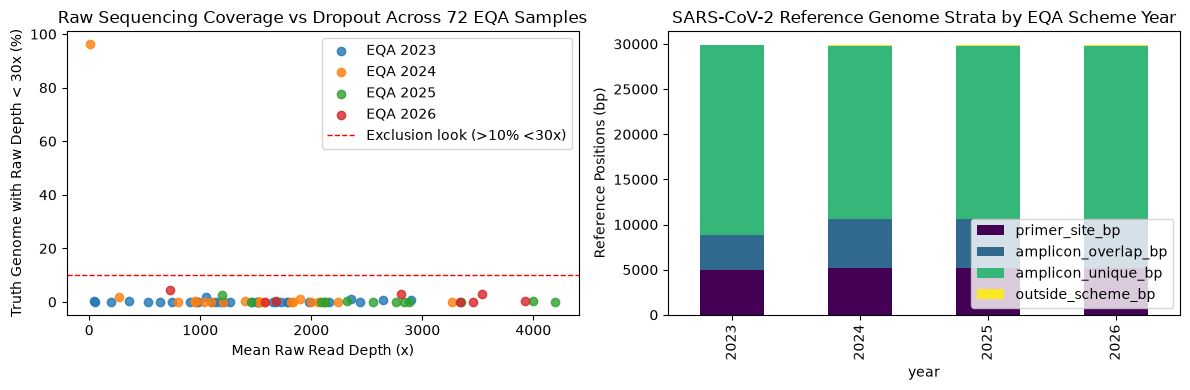

In [63]:
# 2. Raw Sample Depth Eligibility & Excluded Samples
elig_df = pd.read_csv(RAW_ELIGIBILITY_CSV)
print("Samples sorted by fraction of truth genome with raw depth < 30x (top 8 worst):")
display(elig_df.sort_values("raw_Span_lt_30_frac", ascending=False).head(8))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for year, grp in elig_df.groupby("year"):
    axes[0].scatter(grp["mean_raw_depth"], grp["raw_Span_lt_30_frac"] * 100, label=f"EQA {year}", alpha=0.8)
axes[0].axhline(10, color="red", linestyle="--", linewidth=1, label="Exclusion look (>10% <30x)")
axes[0].set_xlabel("Mean Raw Read Depth (x)")
axes[0].set_ylabel("Truth Genome with Raw Depth < 30x (%)")
axes[0].set_title("Raw Sequencing Coverage vs Dropout Across 72 EQA Samples")
axes[0].legend()

# Plot genomic strata proportions
strata_cols = ["primer_site_bp", "amplicon_overlap_bp", "amplicon_unique_bp", "outside_scheme_bp"]
scheme_df[strata_cols].plot(kind="bar", stacked=True, ax=axes[1], colormap="viridis")
axes[1].set_ylabel("Reference Positions (bp)")
axes[1].set_title("SARS-CoV-2 Reference Genome Strata by EQA Scheme Year")
axes[1].legend(loc="lower right")
plt.tight_layout()
plt.show()

In [64]:
# 3. Prototype Equivalence Gate Results
equiv_df = pd.read_csv(EQUIV_CSV)
print("Prototype Equivalence Gate Summary:")
display(equiv_df)

Prototype Equivalence Gate Summary:


,method,sample,reads,seconds,identical
0,adapters,EQA_2026_01,10000,2.4,True
1,adapters,EQA_2026_02,10000,2.3,True
2,adapters,EQA_2026_03,10000,2.2,True
3,adapters,EQA_2026_04,10000,2.3,True
4,adapters,EQA_2026_05,10000,2.5,True
5,adapters,EQA_2026_06,10000,2.2,True
6,adapters,EQA_2026_07,10000,2.3,True
7,adapters,EQA_2026_08,10000,2.2,True
8,sassy,EQA_2026_01,10000,11.5,True
9,sassy,EQA_2026_02,10000,12.2,True
